In [90]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,SimpleRNN,Dense,Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import timeseries_dataset_from_array

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error


In [91]:
df=pd.read_csv("city_day.csv")


In [92]:
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [93]:
df.shape

(29531, 16)

In [94]:
df.columns.to_list()

['City',
 'Date',
 'PM2.5',
 'PM10',
 'NO',
 'NO2',
 'NOx',
 'NH3',
 'CO',
 'SO2',
 'O3',
 'Benzene',
 'Toluene',
 'Xylene',
 'AQI',
 'AQI_Bucket']

In [95]:
df.isnull().sum()

City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [96]:
missing_percentage=(df.isnull().sum() /len(df) *100)
print(missing_percentage.sort_values(ascending=False))

Xylene        61.322001
PM10          37.723071
NH3           34.973418
Toluene       27.229014
Benzene       19.041008
AQI           15.851139
AQI_Bucket    15.851139
PM2.5         15.570079
NOx           14.171549
O3            13.619586
SO2           13.050692
NO2           12.139785
NO            12.129626
CO             6.972334
Date           0.000000
City           0.000000
dtype: float64


In [97]:
features = ["PM2.5","NO","NO2","NOx","CO","SO2","O3","Benzene"]
target = "AQI"

In [98]:
df["Date"]=pd.to_datetime(df["Date"])
city_df=df[df["City"]=="Ahmedabad"].copy()
city_df=city_df.sort_values("Date")
city_df=city_df.set_index("Date")

In [99]:
data=city_df[features+[target]].copy()

In [100]:
data

,PM2.5,NO,NO2,NOx,CO,SO2,O3,Benzene,AQI
Date,,,,,,,,,
2015-01-01,NaN,0.92,18.22,17.15,0.92,27.64,133.36,0.00,NaN
2015-01-02,NaN,0.97,15.69,16.46,0.97,24.55,34.06,3.68,NaN
2015-01-03,NaN,17.40,19.30,29.70,17.40,29.07,30.70,6.80,NaN
2015-01-04,NaN,1.70,18.48,17.97,1.70,18.59,36.08,4.43,NaN
2015-01-05,NaN,22.10,21.42,37.76,22.10,39.33,39.31,7.01,NaN
...,...,...,...,...,...,...,...,...,...
2020-06-27,62.12,9.18,56.35,19.86,0.49,12.44,68.05,1.32,92.0
2020-06-28,31.57,6.37,23.99,16.40,0.52,11.01,26.34,1.37,82.0
2020-06-29,29.75,9.06,25.15,18.92,0.67,12.10,34.99,1.39,74.0


In [101]:
split = int(len(city_df) * 0.8)

train_data = data.iloc[:split].copy()

test_data = data.iloc[split:].copy()

print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)

Training data: (1607, 9)
Testing data: (402, 9)


In [102]:
train_data

,PM2.5,NO,NO2,NOx,CO,SO2,O3,Benzene,AQI
Date,,,,,,,,,
2015-01-01,NaN,0.92,18.22,17.15,0.92,27.64,133.36,0.00,NaN
2015-01-02,NaN,0.97,15.69,16.46,0.97,24.55,34.06,3.68,NaN
2015-01-03,NaN,17.40,19.30,29.70,17.40,29.07,30.70,6.80,NaN
2015-01-04,NaN,1.70,18.48,17.97,1.70,18.59,36.08,4.43,NaN
2015-01-05,NaN,22.10,21.42,37.76,22.10,39.33,39.31,7.01,NaN
...,...,...,...,...,...,...,...,...,...
2019-05-22,27.93,11.44,76.75,50.49,11.44,86.48,54.34,15.60,270.0
2019-05-23,41.39,14.29,89.10,59.76,14.29,105.96,49.70,16.33,323.0
2019-05-24,46.79,14.31,93.27,61.82,14.31,131.04,56.31,15.21,344.0


In [103]:
train_medians=train_data[features].median()
train_data[features]=train_data[features].fillna(train_medians)
test_data[features]=test_data[features].fillna(train_medians)

In [104]:
print(train_data.isnull().sum())
print(test_data.isnull().sum())

PM2.5        0
NO           0
NO2          0
NOx          0
CO           0
SO2          0
O3           0
Benzene      0
AQI        663
dtype: int64
PM2.5       0
NO          0
NO2         0
NOx         0
CO          0
SO2         0
O3          0
Benzene     0
AQI        12
dtype: int64


In [105]:
print("Training AQI available:",
      train_data["AQI"].notna().sum())

print("Testing AQI available:",
      test_data["AQI"].notna().sum())

Training AQI available: 944
Testing AQI available: 390


In [106]:
X_scaler=MinMaxScaler()
X_train_scaled=X_scaler.fit_transform(
    train_data[features])
X_test_scaled=X_scaler.transform(
    test_data[features]
)

In [107]:
y_scaler=MinMaxScaler()
y_train_valid=train_data["AQI"].dropna().values.reshape(-1,1)
y_scaler.fit(y_train_valid)

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](1,)",[2049.]
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](1,)",[48.]
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](1,)",[2001.]
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](1,)",[-0.02]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,944
"scale_ scale_: ndarray of shape (n_features,)Per feature relative scaling of the data. Equivalent to``(max - min) / (X.max(axis=0) - X.min(axis=0))``.. versionadded:: 0.17 *scale_* attribute.","ndarray[float64](1,)",[0.]


In [108]:
X_scaled = np.vstack([
    X_train_scaled,
    X_test_scaled
])

In [109]:
print("X_scaled:", X_scaled.shape)

print("Train features:", X_train_scaled.shape)

print("Test features:", X_test_scaled.shape)

X_scaled: (2009, 8)
Train features: (1607, 8)
Test features: (402, 8)


In [110]:
window_size=7

In [111]:
X_all=timeseries_dataset_from_array(
    data=X_scaled,
    targets=None,
    sequence_length=window_size,
    sequence_stride=1,
    batch_size=None,
    shuffle=False
)
X_all=np.array(list(X_all))

In [112]:
y_all=city_df["AQI"].values
target_indices=np.arange(window_size,len(city_df))

In [113]:
valid_mask = ~np.isnan(y_all[window_size:])
X = X_all[:-1][valid_mask]
y = y_all[window_size:][valid_mask].reshape(-1, 1)
target_indices = target_indices[valid_mask]

In [114]:
print("X_all:", X_all.shape)
print("X:", X.shape)
print("y:", y.shape)
print("Target indices:", target_indices.shape)


X_all: (2003, 7, 8)
X: (1334, 7, 8)
y: (1334, 1)
Target indices: (1334,)


In [115]:
train_mask = target_indices < split
test_mask = target_indices >= split

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (944, 7, 8)
y_train: (944, 1)
X_test: (390, 7, 8)
y_test: (390, 1)


In [116]:
val_split = int(len(X_train) * 0.8)

X_tr = X_train[:val_split]
y_tr = y_train[:val_split]

X_val = X_train[val_split:]
y_val = y_train[val_split:]

print(X_tr.shape)
print(X_val.shape)

(755, 7, 8)
(189, 7, 8)


In [117]:
y_tr_scaled = y_scaler.transform(y_tr)
y_val_scaled = y_scaler.transform(y_val)

In [122]:
print(y_tr_scaled.min(), y_tr_scaled.max())
print(y_val_scaled.min(), y_val_scaled.max())

0.0 1.0
0.03398300849575213 0.8350824587706147


In [118]:
model=Sequential([
    Input(shape=(7,8)),
    SimpleRNN(64, activation="tanh"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)])

In [119]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"])

In [120]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)             │ (None, 64)                  │           4,672 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,785 (26.50 KB)

 Trainable params: 6,785 (26.50 KB)

 Non-trainable params: 0 (0.00 B)

In [129]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)
history = model.fit(
    X_tr,
    y_tr_scaled,
    validation_data=(X_val, y_val_scaled),
    epochs=30,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stop]
)

Epoch 1/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 126330.9531 - mae: 354.5733 - val_loss: 109436.9219 - val_mae: 330.8125
Epoch 2/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 91515.3281 - mae: 301.3056 - val_loss: 72902.7812 - val_mae: 270.0051
Epoch 3/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 58726.0273 - mae: 241.2729 - val_loss: 44446.0000 - val_mae: 210.8221
Epoch 4/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 35510.3516 - mae: 187.5174 - val_loss: 27919.2695 - val_mae: 167.0905
Epoch 5/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 22449.8066 - mae: 148.9810 - val_loss: 16833.7480 - val_mae: 129.7448
Epoch 6/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 13348.2080 - mae: 114.7406 - val_loss: 9644.8223 - val_mae: 98.2079
Epoch 7/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 7524.1147 - mae: 85.9923 - val_loss: 5191.8569 - val_mae: 72.0543
Epoch 8/30
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 4002.5239 - mae: 62.3068 - val_loss: 2243.

In [130]:
print("y_train minimum:", y_tr_scaled.min())
print("y_train maximum:", y_tr_scaled.max())

print("y_val minimum:", y_val_scaled.min())
print("y_val maximum:", y_val_scaled.max())

y_train minimum: 0.0
y_train maximum: 1.0
y_val minimum: 0.03398300849575213
y_val maximum: 0.8350824587706147


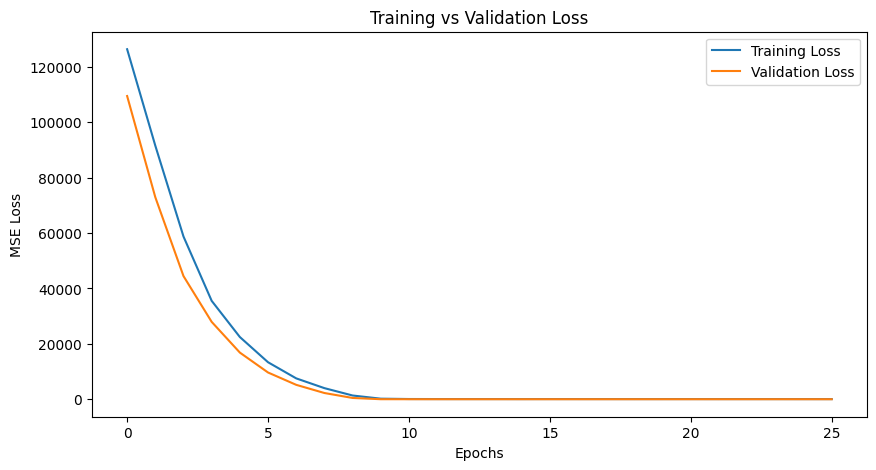

In [131]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

In [ ]:
y_pred=model.predict(X_test)